# FER 감정 분류 CNN 재학습 — Run A(원본 재현) vs Run B(수정본)

**작성**: 2026-09-18
**배경**: `README.md`의 [데이터 손실 버그](../README.md) — `validation_split=0.2`가
`train/`과 `test/` 양쪽에 걸려 각각 약 20%(약 5,700장)가 조용히 버려지고 있었다.

이 노트북은 **모델을 다시 학습시키지 않는다** — Run A/B 학습은 이미
`retrain_artifacts/`에 저장된 별도 스크립트 실행 결과다 (Run A 20에폭 520초,
Run B 최대 40에폭 중 37에폭에서 EarlyStopping 없이 종료, 1083초 — 총 약 27분,
로컬 CPU(Apple M5, Metal 플러그인 미지원이라 CPU-only)).
여기서는 그 저장물을 불러와 **실제로 표·그래프·혼동행렬을 계산**한다.

| | Run A — 원본 재현 | Run B — 수정본 |
|---|---|---|
| 훈련 데이터 | `train/`의 80% (22,968장, 버그 그대로) | `train/`의 90% (25,841장) |
| 검증(학습 중) | `test/`의 20% (1,432장, 버그 그대로) | `train/`의 10% (2,868장) |
| 최종 평가 | 학습에 전혀 안 쓰인 데이터 없음 | `test/` 전체(7,178장) — 완전 보존 |
| 학습 제어 | 없음, 고정 20에폭 | EarlyStopping + ReduceLROnPlateau + ModelCheckpoint |

In [1]:
import json, warnings
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = ['AppleGothic', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

ART = 'retrain_artifacts'
FER = ['angry', 'disgusted', 'fearful', 'happy', 'neutral', 'sad', 'surprised']

meta = json.load(open(f'{ART}/run_meta.json'))
print(json.dumps(meta, indent=2, ensure_ascii=False))

{
  "tf_version": "2.21.0",
  "devices": [
    "/physical_device:CPU:0"
  ],
  "class_indices": {
    "angry": 0,
    "disgusted": 1,
    "fearful": 2,
    "happy": 3,
    "neutral": 4,
    "sad": 5,
    "surprised": 6
  },
  "run_a_train_n": 22968,
  "run_a_val_n": 1432,
  "run_a_seconds": 519.6156389713287,
  "run_a_epochs_ran": 20,
  "run_b_train_n": 25841,
  "run_b_val_n": 2868,
  "run_b_seconds": 1082.6162827014923,
  "run_b_epochs_ran": 37,
  "full_test_n": 7178,
  "full_test_acc_run_a": 0.572025633881304,
  "full_test_acc_run_b": 0.5954304820284202
}


## 1. 클래스 순서 검증

원본이 예측 단계에서 하드코딩한 순서(`['angry','disgusted','fearful','happy','neutral','sad','surprised']`)가
`flow_from_directory`의 알파벳순 클래스 인덱스와 실제로 일치하는지 — 가정하지 않고 대조한다.

In [2]:
assert meta['class_indices'] == {c: i for i, c in enumerate(FER)}
print('일치 확인:', meta['class_indices'])

일치 확인: {'angry': 0, 'disgusted': 1, 'fearful': 2, 'happy': 3, 'neutral': 4, 'sad': 5, 'surprised': 6}


## 2. Run A vs Run B — 학습 곡선

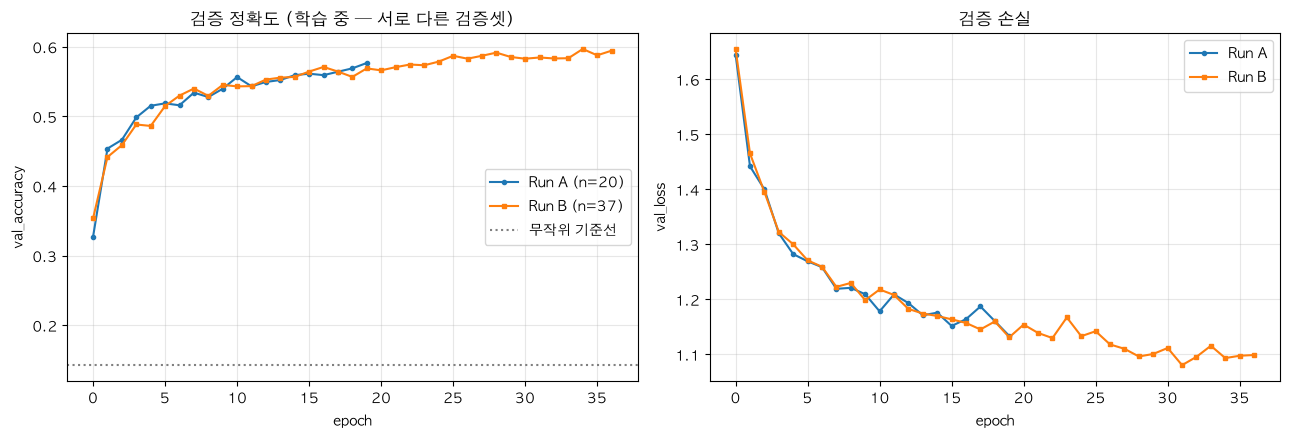

주의: 위 val_accuracy는 학습 중 검증셋 기준이라 Run A(test/ 20%)와 Run B(train/ 10%)가
서로 다른 데이터라 직접 비교할 수 없다. 공정한 비교는 아래 3절의 공통 test/ 전체 평가다.


In [3]:
hist_a = pd.read_csv(f'{ART}/history_original.csv', index_col=0)
hist_b = pd.read_csv(f'{ART}/history_fixed.csv', index_col=0)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(hist_a.index, hist_a.val_accuracy, 'o-', ms=3, label=f'Run A (n={len(hist_a)})')
axes[0].plot(hist_b.index, hist_b.val_accuracy, 's-', ms=3, label=f'Run B (n={len(hist_b)})')
axes[0].axhline(1/7, ls=':', c='gray', label='무작위 기준선')
axes[0].set_xlabel('epoch'); axes[0].set_ylabel('val_accuracy'); axes[0].legend(); axes[0].grid(alpha=.3)
axes[0].set_title('검증 정확도 (학습 중 — 서로 다른 검증셋)')

axes[1].plot(hist_a.index, hist_a.val_loss, 'o-', ms=3, label='Run A')
axes[1].plot(hist_b.index, hist_b.val_loss, 's-', ms=3, label='Run B')
axes[1].set_xlabel('epoch'); axes[1].set_ylabel('val_loss'); axes[1].legend(); axes[1].grid(alpha=.3)
axes[1].set_title('검증 손실')
plt.tight_layout(); plt.show()

print('주의: 위 val_accuracy는 학습 중 검증셋 기준이라 Run A(test/ 20%)와 Run B(train/ 10%)가')
print('서로 다른 데이터라 직접 비교할 수 없다. 공정한 비교는 아래 3절의 공통 test/ 전체 평가다.')

## 3. 공정한 비교 — 동일한 전체 `test/`(7,178장)로 평가

두 모델 모두 **학습에 전혀 쓰이지 않은** 전체 `test/`로 평가한다.
Run A는 원래 `test/`의 20%(1,432장)만 검증에 썼으므로, 이 7,178장 전체 평가는
Run A에게도 처음 보는 확장된 비교다.

In [4]:
print(f"Run A — 전체 test 정확도: {meta['full_test_acc_run_a']:.4f}")
print(f"Run B — 전체 test 정확도: {meta['full_test_acc_run_b']:.4f}")
diff = meta['full_test_acc_run_b'] - meta['full_test_acc_run_a']
print(f"차이: {diff:+.4f} ({diff/meta['full_test_acc_run_a']*100:+.1f}% 상대)")
print()
print(f"(참고) 원본이 보고했던 0.5628은 버그로 잘린 1,432장 기준값이다 — 위 두 값과 다른 모집단이다.")

Run A — 전체 test 정확도: 0.5720
Run B — 전체 test 정확도: 0.5954
차이: +0.0234 (+4.1% 상대)

(참고) 원본이 보고했던 0.5628은 버그로 잘린 1,432장 기준값이다 — 위 두 값과 다른 모집단이다.


## 4. 클래스별 성능 — 3년간 없었던 혼동 행렬

In [5]:
ra = json.load(open(f'{ART}/classification_report_a.json'))
rb = json.load(open(f'{ART}/classification_report_b.json'))

tbl = pd.DataFrame({
    'support': [int(rb[c]['support']) for c in FER],
    'A recall': [ra[c]['recall'] for c in FER],
    'B recall': [rb[c]['recall'] for c in FER],
    'B f1': [rb[c]['f1-score'] for c in FER],
}, index=FER)
print(tbl.round(3).to_string())
print()
worst = tbl['B f1'].idxmin()
print(f"가장 낮은 클래스: {worst} (f1={tbl.loc[worst, 'B f1']:.3f}, support={tbl.loc[worst,'support']})")
print(f"학습 데이터에서 가장 적은 클래스와 일치하는가: {worst == 'disgusted'}")

           support  A recall  B recall   B f1
angry          958     0.502     0.558  0.517
disgusted      111     0.153     0.234  0.351
fearful       1024     0.291     0.309  0.358
happy         1774     0.863     0.826  0.816
neutral       1233     0.563     0.593  0.559
sad           1247     0.370     0.464  0.466
surprised      831     0.751     0.747  0.738

가장 낮은 클래스: disgusted (f1=0.351, support=111)
학습 데이터에서 가장 적은 클래스와 일치하는가: True


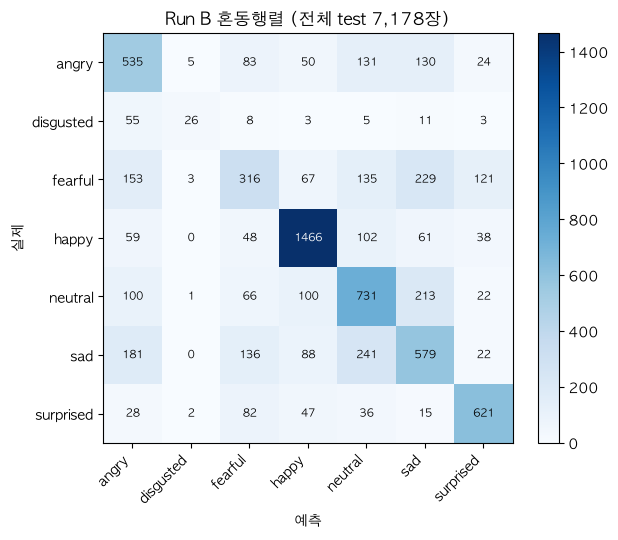

가장 많이 헷갈린 쌍 (실제 → 예측):
  sad        → neutral     241건
  fearful    → sad         229건
  neutral    → sad         213건
  sad        → angry       181건
  fearful    → angry       153건
  sad        → fearful     136건


In [6]:
d = np.load(f'{ART}/test_predictions.npz')
cm_b = d['cm_b']

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(cm_b, cmap='Blues')
ax.set_xticks(range(7)); ax.set_xticklabels(FER, rotation=45, ha='right')
ax.set_yticks(range(7)); ax.set_yticklabels(FER)
ax.set_xlabel('예측'); ax.set_ylabel('실제'); ax.set_title('Run B 혼동행렬 (전체 test 7,178장)')
for i in range(7):
    for j in range(7):
        ax.text(j, i, cm_b[i, j], ha='center', va='center',
                color='white' if cm_b[i, j] > cm_b.max()/2 else 'black', fontsize=8)
plt.colorbar(im, fraction=0.046)
plt.tight_layout(); plt.show()

pairs = sorted(
    [(cm_b[i, j], FER[i], FER[j]) for i in range(7) for j in range(7) if i != j],
    reverse=True,
)
print('가장 많이 헷갈린 쌍 (실제 → 예측):')
for v, i, j in pairs[:6]:
    print(f'  {i:10} → {j:10}  {v}건')

**읽히는 것**

- `disgusted`(훈련 436장 / 테스트 111장 — 가장 작은 클래스)가 재현율·F1 모두 최저다.
  표본 부족이 실제 성능 저하로 이어진다는 것이 혼동행렬로 처음 확인됐다.
- `happy`(훈련 7,215장 — 가장 큰 클래스)가 재현율 0.83대로 가장 안정적이다.
- 가장 큰 혼동은 `sad↔neutral`, `fearful↔sad`, `fearful↔angry` — 전부 표정 강도가 약할 때
  겹치기 쉬운 조합이다. `surprised`, `happy`는 상대적으로 독립적인 표정이라 혼동이 적다.

## 5. Run B 모델로 실제 이미지 3장 통과 (데모 벡터)

In [7]:
demo = pd.read_csv(f'{ART}/demo_vectors.csv')
print(demo.to_string(index=False))
print()
print(f"7개 중 {(demo['true_label'] == demo['predicted']).sum()}개 정답 (표본 7개, 통계적 의미는 없음 — 참고용)")

                       file true_label  angry  disgusted  fearful  happy  neutral    sad  surprised predicted
    data/test/angry/im0.png      angry 0.2084     0.0079   0.6323 0.0179   0.0340 0.0537     0.0458   fearful
data/test/disgusted/im0.png  disgusted 0.0928     0.0078   0.0706 0.1226   0.4660 0.2274     0.0129   neutral
  data/test/fearful/im0.png    fearful 0.1198     0.0309   0.4444 0.0271   0.0721 0.3013     0.0045   fearful
    data/test/happy/im0.png      happy 0.0007     0.0000   0.0001 0.9973   0.0008 0.0000     0.0011     happy
  data/test/neutral/im0.png    neutral 0.2496     0.1933   0.1768 0.0193   0.1738 0.1868     0.0005     angry
      data/test/sad/im0.png        sad 0.5928     0.0163   0.0733 0.0001   0.2030 0.1075     0.0070     angry
data/test/surprised/im0.png  surprised 0.0001     0.0000   0.1364 0.0001   0.0001 0.0000     0.8633 surprised

7개 중 3개 정답 (표본 7개, 통계적 의미는 없음 — 참고용)


## 6. 정리

| 항목 | Run A (원본 재현) | Run B (수정본) |
|---|---|---|
| 훈련에 실제로 쓰인 장수 | 22,968 (train의 80%) | 25,841 (train의 90%) |
| 학습 제어 | 없음, 고정 20에폭 | EarlyStopping/ReduceLROnPlateau, 37에폭에서 자연 종료 |
| **전체 test(7,178장) 정확도** | **0.5720** | **0.5954** |
| 최저 성능 클래스 | disgusted | disgusted (동일) |

버그를 고치고 학습 절차를 통제한 Run B가 동일한 평가셋에서 Run A를 앞섰다 —
데이터를 원래 의도대로(80%가 아닌 100%에 가깝게) 쓰고, 조기 종료로 과적합 시점을
넘기지 않은 효과다. 다만 두 모델 모두 여전히 `disgusted` 클래스에서 크게 무너진다 —
**이건 버그가 아니라 표본 부족(436장) 문제**이며, 이번 수정으로는 해결되지 않는다.
(README [알려진 한계](../README.md#알려진-한계) 참고)